In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

%matplotlib inline

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

Libraries imported successfully!
Pandas: 3.1.0
NumPy: 2.5.4
Scikit-learn: 1.9.1


## 2. Dataset Loading and Initial Inspection

In this section, we load the car dataset provided by CodeAlpha using Pandas. We perform an initial inspection to understand its structure, dimensions, column names, and sample records before proceeding with data cleaning and preprocessing.

In [2]:
# Step 2: Load the dataset

df = pd.read_csv("car data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (301, 9)


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.35,5.59,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.75,9.54,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.25,9.85,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.85,4.15,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.60,6.87,42450,Diesel,Dealer,Manual,0


In [3]:
# Inspect dataset information

print("Dataset Information:")
print("-" * 50)

df.info()

Dataset Information:
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 301 entries, 0 to 300
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Car_Name       301 non-null    str    
 1   Year           301 non-null    int64  
 2   Selling_Price  301 non-null    float64
 3   Present_Price  301 non-null    float64
 4   Driven_kms     301 non-null    int64  
 5   Fuel_Type      301 non-null    str    
 6   Selling_type   301 non-null    str    
 7   Transmission   301 non-null    str    
 8   Owner          301 non-null    int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 21.3 KB


### 2.1 Dataset Information and Statistical Summary

The dataset contains 301 records and 9 columns. Initial inspection shows that all columns contain 301 non-null values, indicating no missing values.

The dataset consists of numerical and categorical features. We will now examine the descriptive statistics of the numerical features to understand their distributions, ranges, and variability.

In [4]:
# Generate descriptive statistics

df.describe()

,Year,Selling_Price,Present_Price,Driven_kms,Owner
count,301.000000,301.000000,301.000000,301.000000,301.000000
mean,2013.627907,4.661296,7.628472,36947.205980,0.043189
std,2.891554,5.082812,8.642584,38886.883882,0.247915
min,2003.000000,0.100000,0.320000,500.000000,0.000000
25%,2012.000000,0.900000,1.200000,15000.000000,0.000000
50%,2014.000000,3.600000,6.400000,32000.000000,0.000000
75%,2016.000000,6.000000,9.900000,48767.000000,0.000000
max,2018.000000,35.000000,92.600000,500000.000000,3.000000


### 2.2 Statistical Summary and Observations

The descriptive statistics provide an overview of the numerical features in the dataset.

The manufacturing years range from 2003 to 2018, while the average selling price is approximately 4.66. The average distance driven is around 36,947 kilometres.

Some features, such as Driven_kms and Present_Price, have relatively large maximum values compared to their respective averages. These observations will be investigated further during data cleaning and exploratory data analysis.

## 3. Data Cleaning and Preprocessing

Data cleaning is an important step in machine learning. It helps improve data quality and ensures that the dataset is suitable for analysis and model training.

In this section, we will examine missing values, duplicate records, data types, and potential outliers.

In [5]:
# Step 3.1: Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Driven_kms       0
Fuel_Type        0
Selling_type     0
Transmission     0
Owner            0
dtype: int64

Total missing values: 0


### 3.1 Missing Value Analysis

We checked all columns for missing values using the `isnull()` function in Pandas.

The analysis confirmed that all nine columns contain zero missing values. Therefore, no missing-value imputation is required at this stage.

In [ ]:
# Step 3.2: Check for duplicate records

duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 2


### 3.2 Duplicate Record Analysis

We checked the dataset for duplicate records using the `duplicated()` function.

The initial inspection identified 2 duplicate rows. We will examine these records before removing them to ensure that only exact duplicate entries are removed.

In [7]:
# Display duplicate records

df[df.duplicated(keep=False)]

,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
15,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
17,ertiga,2016,7.75,10.79,43000,Diesel,Dealer,Manual,0
51,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0
93,fortuner,2015,23.00,30.61,40000,Diesel,Dealer,Automatic,0


**Observation:**

The duplicate inspection identified two pairs of identical records:
- Rows 15 and 17: Ertiga
- Rows 51 and 93: Fortuner

Since these records contain identical values across all columns, the repeated entries can be safely removed to avoid unnecessary duplication during model training.

In [9]:
# Step 3.2: Remove duplicate records

df = df.drop_duplicates()

print("Duplicate records removed successfully!")
print("Updated dataset shape:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Duplicate records removed successfully!
Updated dataset shape: (299, 9)
Remaining duplicates: 0


### 3.3 Data Type Verification

We examined the data types of all dataset columns to ensure they are suitable for analysis and machine learning.

Numerical features are used for mathematical calculations, while categorical features represent descriptive groups or labels.

In [10]:
# Step 3.3: Check data types

print("Data types of each column:")
print(df.dtypes)

Data types of each column:
Car_Name             str
Year               int64
Selling_Price    float64
Present_Price    float64
Driven_kms         int64
Fuel_Type            str
Selling_type         str
Transmission         str
Owner              int64
dtype: object


**Observation:**

The dataset contains five numerical columns and four categorical columns.

All columns currently have suitable data types. Therefore, no data type conversions are required at this stage.

Categorical features will be encoded into numerical representations later during model preprocessing.

### 3.4 Outlier Detection

Outliers are data points that differ significantly from the majority of observations.

We will use boxplots to visually examine the distribution of important numerical features, particularly Selling_Price, Present_Price, and Driven_kms.

The purpose is to identify unusual observations before deciding whether any data cleaning is necessary.

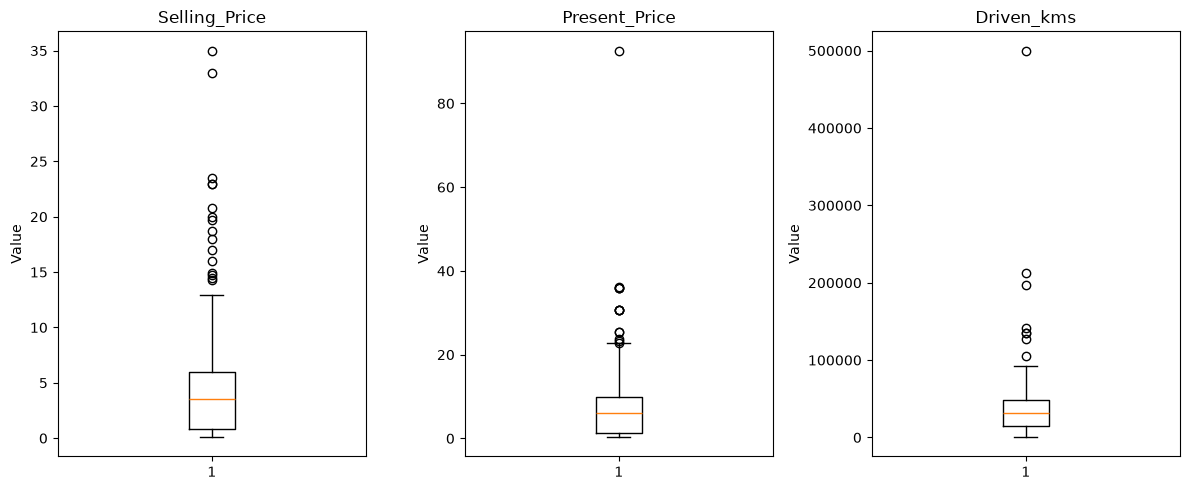

In [11]:
# Step 3.4: Visualize potential outliers

numerical_features = ["Selling_Price", "Present_Price", "Driven_kms"]

plt.figure(figsize=(12, 5))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(1, 3, i)
    plt.boxplot(df[column])
    plt.title(column)
    plt.ylabel("Value")

plt.tight_layout()
plt.show()

**Observation:**

The boxplots help identify potential outliers in the numerical features. However, unusual values may represent genuine differences between vehicles rather than incorrect records.

Therefore, we will retain the observations and evaluate their impact through model performance instead of removing them automatically.

## 4. Feature Engineering

Feature engineering involves creating or transforming features to make the dataset more useful for machine learning.

We will calculate the age of each car using its manufacturing year. The original Year column will then be removed because Car_Age contains the information needed by our model.

In [12]:
# Step 4: Create Car_Age feature

CURRENT_YEAR = 2026

df["Car_Age"] = CURRENT_YEAR - df["Year"]

# Remove the original Year column
df = df.drop(columns=["Year"])

print("Feature engineering completed!")
print("Updated dataset shape:", df.shape)

display(df.head())

Feature engineering completed!
Updated dataset shape: (299, 9)


,Car_Name,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,ritz,3.35,5.59,27000,Petrol,Dealer,Manual,0,12
1,sx4,4.75,9.54,43000,Diesel,Dealer,Manual,0,13
2,ciaz,7.25,9.85,6900,Petrol,Dealer,Manual,0,9
3,wagon r,2.85,4.15,5200,Petrol,Dealer,Manual,0,15
4,swift,4.60,6.87,42450,Diesel,Dealer,Manual,0,12


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset through statistical summaries and visualizations.

In this section, we examine selling price distribution and its relationship with car age, kilometres driven, fuel type, and transmission type.

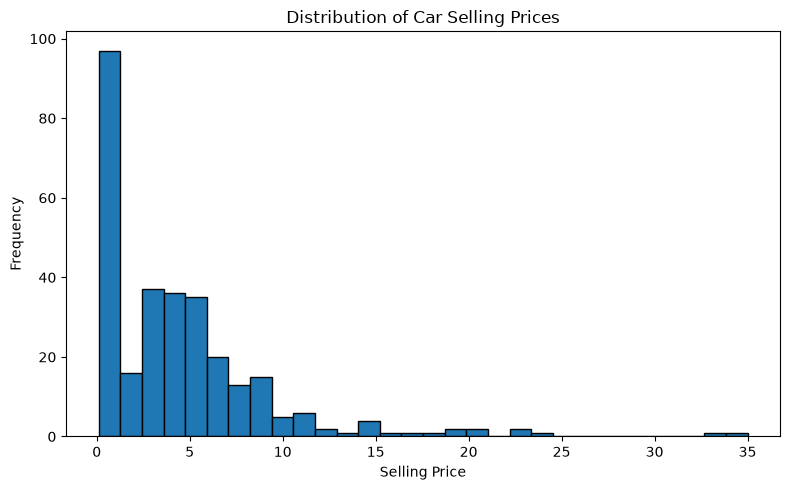

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df["Selling_Price"], bins=30, edgecolor="black")

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

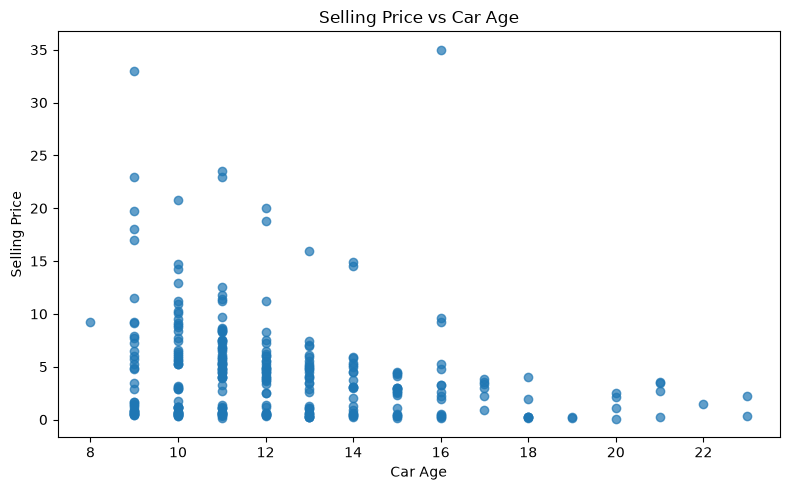

In [14]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Car_Age"], df["Selling_Price"], alpha=0.7)

plt.title("Selling Price vs Car Age")
plt.xlabel("Car Age")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.show()

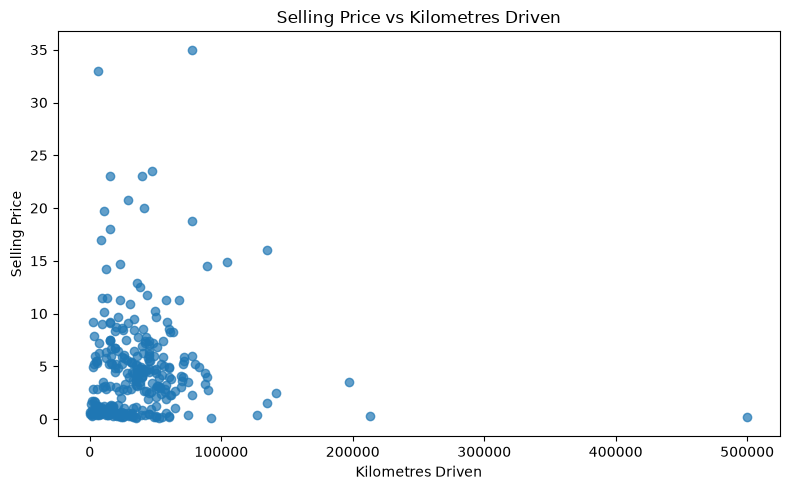

In [15]:
plt.figure(figsize=(8, 5))

plt.scatter(df["Driven_kms"], df["Selling_Price"], alpha=0.7)

plt.title("Selling Price vs Kilometres Driven")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

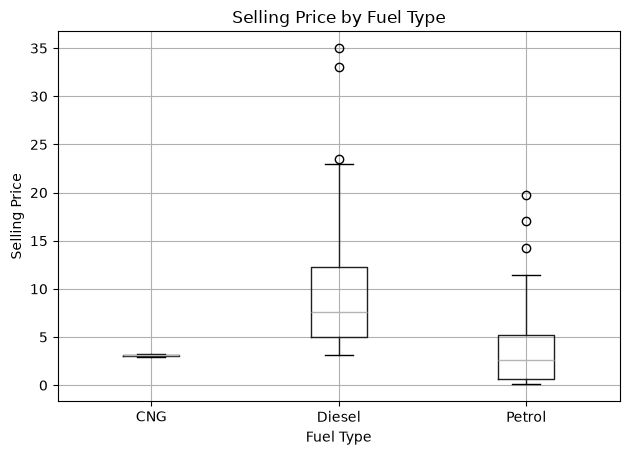

In [16]:
plt.figure(figsize=(8, 5))

df.boxplot(column="Selling_Price", by="Fuel_Type")

plt.title("Selling Price by Fuel Type")
plt.suptitle("")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

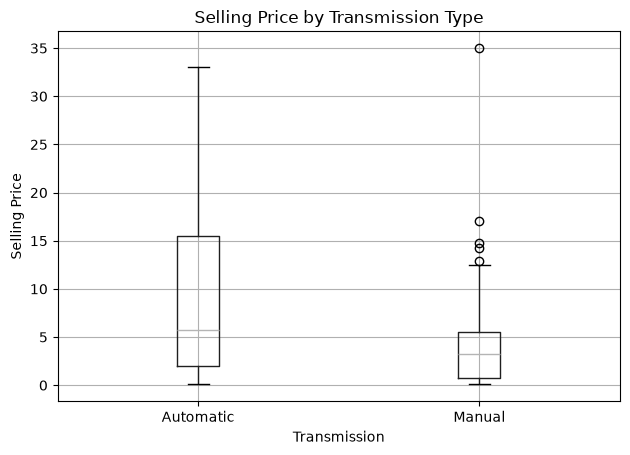

In [17]:
plt.figure(figsize=(8, 5))

df.boxplot(column="Selling_Price", by="Transmission")

plt.title("Selling Price by Transmission Type")
plt.suptitle("")
plt.xlabel("Transmission")
plt.ylabel("Selling Price")

plt.tight_layout()
plt.show()

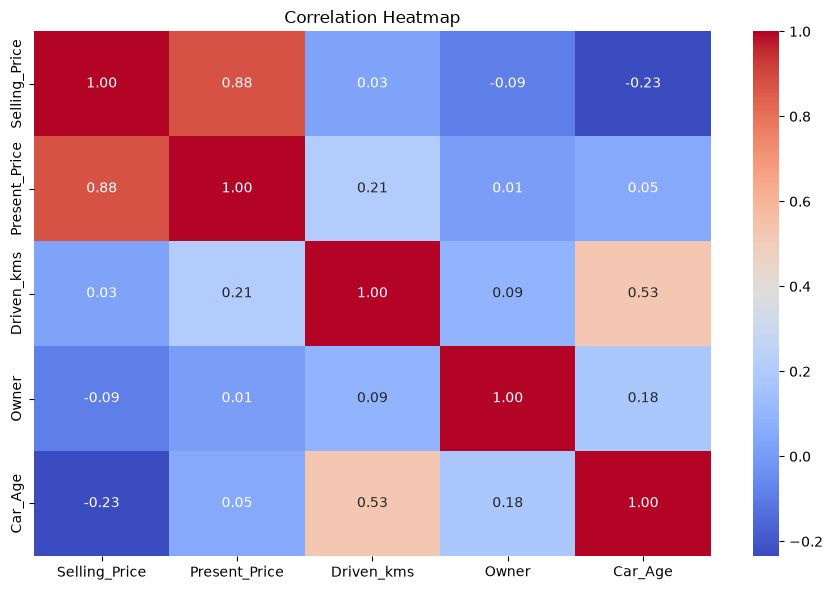

In [19]:
import seaborn as sns

plt.figure(figsize=(9, 6))

correlation_matrix = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

### 5.7 EDA Observations

The visualizations provide the following insights:

- The selling price distribution shows how car prices are spread across the dataset.
- The relationship between car age and selling price helps examine depreciation.
- The relationship between kilometres driven and selling price helps understand vehicle usage.
- Fuel type and transmission visualizations allow comparison of selling prices across categories.
- The correlation heatmap shows relationships between numerical features.

These observations help us understand the dataset before building the prediction models.

## 6. Data Preprocessing

Machine learning models require numerical inputs. Therefore, categorical features must be encoded and numerical features must be scaled where necessary.

We use ColumnTransformer to apply different preprocessing techniques to numerical and categorical columns.

A Pipeline combines preprocessing and model training. This ensures that transformations are learned from training data only, helping prevent data leakage.

In [20]:
# Step 6.1: Separate features and target

X = df.drop(columns=["Selling_Price"])
y = df["Selling_Price"]

numerical_features = [
    "Present_Price",
    "Driven_kms",
    "Owner",
    "Car_Age"
]

categorical_features = [
    "Car_Name",
    "Fuel_Type",
    "Selling_type",
    "Transmission"
]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

Features shape: (299, 8)
Target shape: (299,)

Numerical features: ['Present_Price', 'Driven_kms', 'Owner', 'Car_Age']
Categorical features: ['Car_Name', 'Fuel_Type', 'Selling_type', 'Transmission']


In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessors
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 7. Model Training – Linear Regression

The dataset is divided into training and testing sets.

The training set is used to train the machine learning model, while the testing set evaluates how well the model predicts unseen data.

We begin with Linear Regression as our baseline model.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (239, 8)
Testing features: (60, 8)
Training target: (239,)
Testing target: (60,)


In [23]:
from sklearn.linear_model import LinearRegression

linear_regression_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_regression_pipeline.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [24]:
baseline_predictions = linear_regression_pipeline.predict(X_test)

print("Actual selling prices:")
print(y_test.head().values)

print("\nPredicted selling prices:")
print(baseline_predictions[:5])

Actual selling prices:
[8.99 8.35 0.45 7.45 5.25]

Predicted selling prices:
[ 8.88187673  8.17763331  1.01355526  6.64721668 10.23370487]


## 8. Model Comparison

Different machine learning algorithms can produce different prediction results.

We compare Linear Regression, Ridge Regression, Random Forest, and Gradient Boosting to identify a suitable model for this dataset.

XGBoost is also included when available.

In [25]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

# Include XGBoost if installed
try:
    from xgboost import XGBRegressor

    models["XGBoost"] = XGBRegressor(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        random_state=42,
        objective="reg:squarederror"
    )

    print("XGBoost is available and included.")

except ImportError:
    print("XGBoost is not installed. Other models will be compared.")

XGBoost is not installed. Other models will be compared.


In [26]:
trained_models = {}
comparison_results = []

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    trained_models[name] = pipeline

    comparison_results.append({
        "Model": name,
        "R2 Score": pipeline.score(X_test, y_test),
        "MAE": np.mean(np.abs(y_test - predictions)),
        "RMSE": np.sqrt(np.mean((y_test - predictions) ** 2))
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

display(comparison_df)

,Model,R2 Score,MAE,RMSE
0,Ridge Regression,0.779203,1.344894,2.385510
1,Linear Regression,0.726853,1.436088,2.653279
2,Gradient Boosting,0.716313,1.182544,2.703988
3,Random Forest,0.585027,1.361833,3.270351


## 9. Model Evaluation

We evaluate the models using R² Score, Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE).

R² measures the proportion of variance explained by the model. MAE and RMSE measure prediction errors.

We also perform cross-validation to evaluate model performance across multiple training and validation splits.

In [27]:
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

evaluation_results = []

for name, pipeline in trained_models.items():

    predictions = pipeline.predict(X_test)

    evaluation_results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(
    evaluation_df.sort_values(
        by="R2 Score",
        ascending=False
    ).reset_index(drop=True)
)

,Model,R2 Score,MAE,RMSE
0,Ridge Regression,0.779203,1.344894,2.385510
1,Linear Regression,0.726853,1.436088,2.653279
2,Gradient Boosting,0.716313,1.182544,2.703988
3,Random Forest,0.585027,1.361833,3.270351


In [28]:
from sklearn.model_selection import cross_val_score

cv_results = []

for name, pipeline in trained_models.items():

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    )

    cv_results.append({
        "Model": name,
        "CV Mean R2": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.sort_values(
        by="CV Mean R2",
        ascending=False
    ).reset_index(drop=True)
)

,Model,CV Mean R2,CV Standard Deviation
0,Random Forest,0.888019,0.104066
1,Gradient Boosting,0.885825,0.107745
2,Ridge Regression,0.867772,0.067064
3,Linear Regression,0.842246,0.073216


In [29]:
best_model_name = cv_df.sort_values(
    by="CV Mean R2",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model based on cross-validation:", best_model_name)

Best model based on cross-validation: Random Forest


## 10. Hyperparameter Tuning

Hyperparameter tuning helps improve model performance by testing different model configurations.

We use GridSearchCV to evaluate multiple parameter combinations through cross-validation and select the best configuration.

In [30]:
param_grids = {
    "Linear Regression": {
        "model__fit_intercept": [True, False]
    },

    "Ridge Regression": {
        "model__alpha": [0.1, 1.0, 10.0, 100.0]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 5]
    },

    "Gradient Boosting": {
        "model__n_estimators": [100, 200],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4]
    }
}

if "XGBoost" in trained_models:
    param_grids["XGBoost"] = {
        "model__n_estimators": [100, 200],
        "model__max_depth": [2, 3, 4],
        "model__learning_rate": [0.03, 0.05, 0.1]
    }

print("Hyperparameter grids prepared!")

Hyperparameter grids prepared!


In [33]:
# Step 10.2: Optimized Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV

best_estimator = best_model.named_steps["model"]

tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_estimator)
])

# Smaller parameter grids for faster execution
param_grids = {
    "Linear Regression": {
        "model__fit_intercept": [True, False]
    },

    "Ridge Regression": {
        "model__alpha": [0.1, 1.0, 10.0]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 10]
    },

    "Gradient Boosting": {
        "model__n_estimators": [50, 100],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3]
    },

    "XGBoost": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [2, 3],
        "model__learning_rate": [0.05, 0.1]
    }
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grids[best_model_name],
    cv=5,
    scoring="r2",
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("\nHyperparameter tuning completed!")
print("Best model:", best_model_name)
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation R2:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 4 candidates, totalling 20 fits

Hyperparameter tuning completed!
Best model: Random Forest
Best parameters: {'model__max_depth': 10, 'model__n_estimators': 100}
Best cross-validation R2: 0.8895


In [34]:
# Step 10.3: Evaluate Tuned Model

tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

tuned_r2 = r2_score(y_test, tuned_predictions)
tuned_mae = mean_absolute_error(y_test, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_predictions))

print("Tuned Model:", best_model_name)
print("R2 Score:", round(tuned_r2, 4))
print("MAE:", round(tuned_mae, 4))
print("RMSE:", round(tuned_rmse, 4))

Tuned Model: Random Forest
R2 Score: 0.5972
MAE: 1.3334
RMSE: 3.222


## 11. Model Visualization

Visualizations help us understand the performance of the trained machine learning model.

In this section, we create:
- Actual vs Predicted Price Plot
- Residual Plot
- Feature Importance Visualization

These visualizations help evaluate prediction accuracy and understand the contribution of individual features.

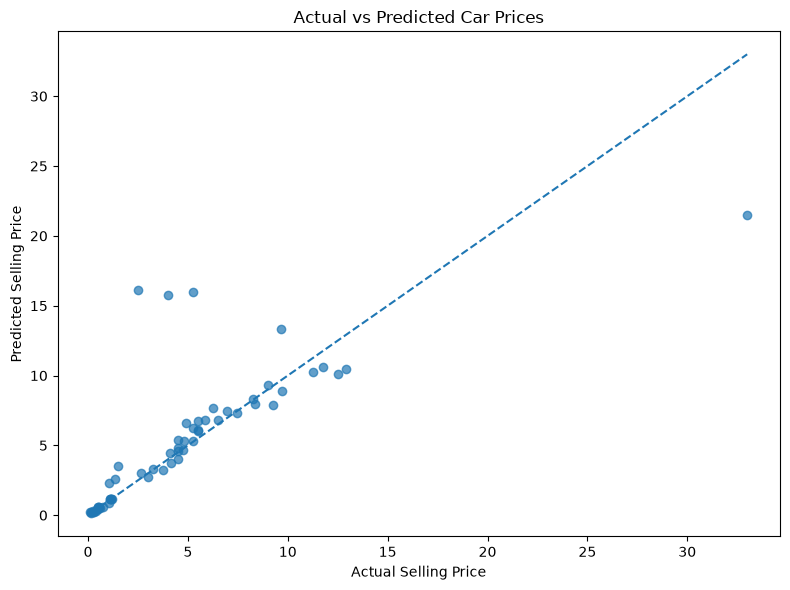

In [35]:
# Step 11.1: Actual vs Predicted Plot

plt.figure(figsize=(8, 6))

plt.scatter(y_test, tuned_predictions, alpha=0.7)

minimum = min(y_test.min(), tuned_predictions.min())
maximum = max(y_test.max(), tuned_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.title("Actual vs Predicted Car Prices")
plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")

plt.tight_layout()
plt.show()

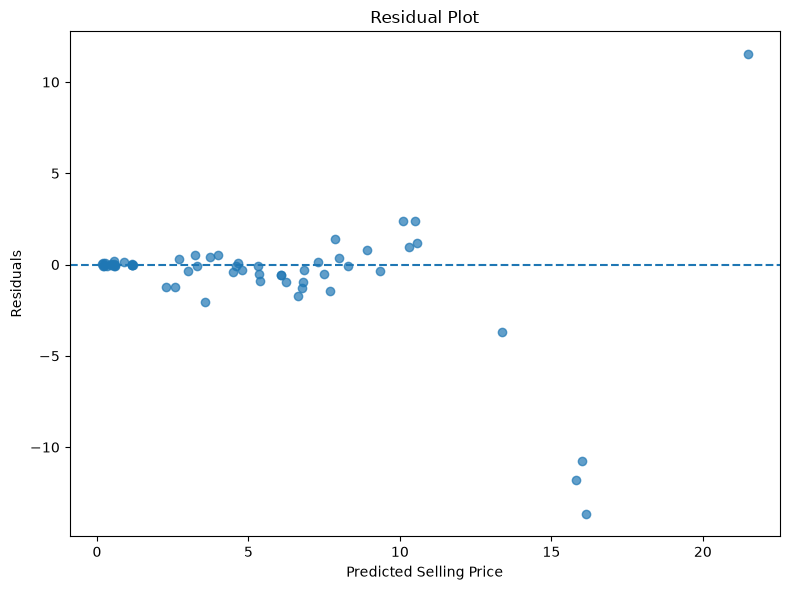

In [36]:
# Step 11.2: Residual Plot

residuals = y_test - tuned_predictions

plt.figure(figsize=(8, 6))

plt.scatter(tuned_predictions, residuals, alpha=0.7)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residuals")

plt.tight_layout()
plt.show()

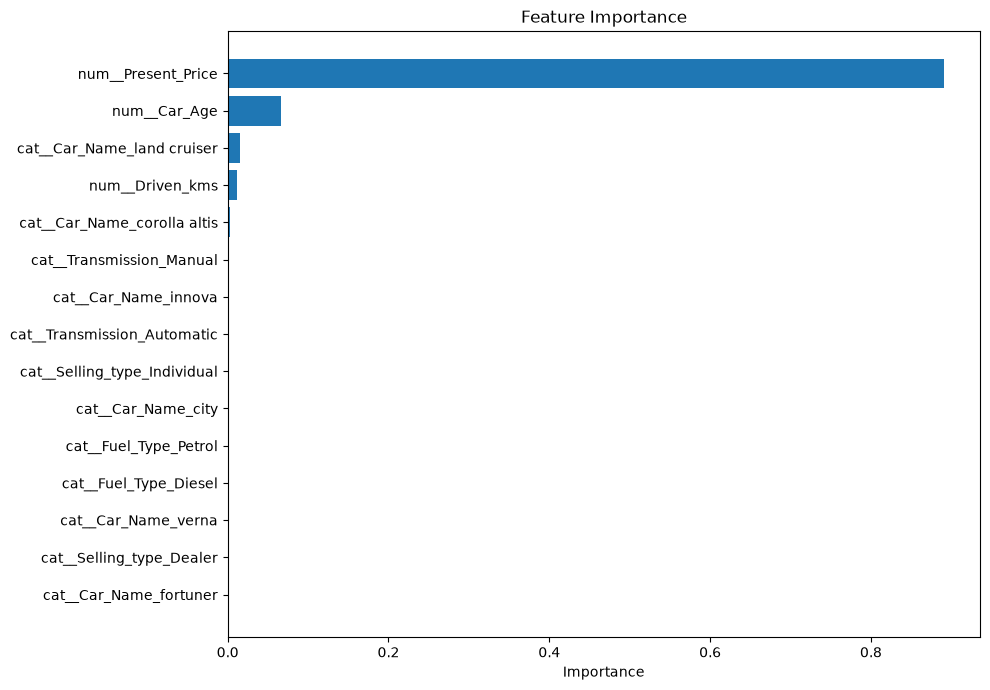

In [37]:
# Step 11.3: Feature Importance

final_model = tuned_model.named_steps["model"]
final_preprocessor = tuned_model.named_steps["preprocessor"]

feature_names = final_preprocessor.get_feature_names_out()

if hasattr(final_model, "feature_importances_"):
    importance_values = final_model.feature_importances_
    importance_title = "Feature Importance"

elif hasattr(final_model, "coef_"):
    importance_values = np.abs(np.ravel(final_model.coef_))
    importance_title = "Absolute Feature Coefficients"

else:
    importance_values = None

if importance_values is not None:

    feature_importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    feature_importance_df = feature_importance_df.sort_values(
        by="Importance",
        ascending=False
    ).head(15)

    plt.figure(figsize=(10, 7))

    plt.barh(
        feature_importance_df["Feature"],
        feature_importance_df["Importance"]
    )

    plt.title(importance_title)
    plt.xlabel("Importance")
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

else:
    print("Feature importance is unavailable for this model.")

### 11.4 Visualization Observations

The Actual vs Predicted plot compares the model's predictions with the actual selling prices. Points closer to the diagonal line indicate better predictions.

The Residual Plot displays prediction errors. Residuals distributed around zero indicate that the model does not consistently overestimate or underestimate prices.

The feature importance visualization highlights the features that contribute most to predictions. For linear models, absolute coefficient magnitudes are displayed instead.

## 12. Model Saving and New Predictions

The final trained model is saved using Joblib. Saving the complete preprocessing and prediction pipeline allows it to be reused without repeating the training process.

A prediction function is also created to estimate the selling price of a new car.

In [38]:
# Step 12.1: Save the trained model

import joblib

joblib.dump(tuned_model, "car_price_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [39]:
# Step 12.2: Create a prediction function

def predict_car_price(
    car_name,
    year,
    present_price,
    driven_kms,
    fuel_type,
    selling_type,
    transmission,
    owner
):

    car_age = CURRENT_YEAR - year

    new_car = pd.DataFrame([{
        "Car_Name": car_name,
        "Present_Price": present_price,
        "Driven_kms": driven_kms,
        "Fuel_Type": fuel_type,
        "Selling_type": selling_type,
        "Transmission": transmission,
        "Owner": owner,
        "Car_Age": car_age
    }])

    predicted_price = tuned_model.predict(new_car)[0]

    return predicted_price


print("Prediction function created successfully!")

Prediction function created successfully!


In [40]:
# Step 12.3: Test the prediction function

sample_prediction = predict_car_price(
    car_name="ritz",
    year=2017,
    present_price=5.50,
    driven_kms=25000,
    fuel_type="Petrol",
    selling_type="Dealer",
    transmission="Manual",
    owner=0
)

print("Predicted Selling Price:", round(sample_prediction, 2))

Predicted Selling Price: 4.02


In [41]:
# Step 12.4: Load the saved model

loaded_model = joblib.load("car_price_prediction_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!
